# BTC market states, structural checks, and five-day risk forecasts

This notebook keeps the core mathematics inline for an interview walkthrough.
Sections 1–6 build causal states and describe a fixed 2023 transition matrix.
Section 7 performs the development-only CK diagnostic (Part B). Sections 8–10
implement the independently frozen prediction workflow (Part A): mature labels,
three rolling forecasters, and paired scoring. Sections 11–12 complete Part B: residence times, joint Holm decisions, and fixed additional development windows.

**Development result:** Among 360 candidate origins in January 1–December 26,
2023, 321 non-risk origins were eligible and scored. Brier losses were 0.253410
(Markov), 0.255005 (pooled frequency), and 0.255398 (direct-state frequency).
The primary difference was +0.001988, with a 95% paired calendar-bootstrap
interval [-0.003013, +0.007037]. The interval includes zero: this development
replay does not establish predictive improvement. The parameters were not
changed in response to these scores.

**Boundaries:** 2020–2023 was already used for development. This notebook loads
no prices dated 2024 or later. The 2023 descriptive matrix is not used as an
earlier forecast. Part A methods update causally at every origin. Development-only Part B does not delay or modify Part A. See the protocol index and current status
for the actual frozen commit and the scheduled October 7 holdout gate.


**Part B development result:** Neither primary implication is rejected at the declared 0.05 level. This is non-rejection, not evidence that the process is proven Markov. None of the eight auxiliary diagnostics rejects after their separate Holm adjustment. Exact values are in sections 11–12.

In [1]:
from pathlib import Path
import hashlib
import sys
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path.cwd() if (Path.cwd() / "AGENTS.md").exists() else Path.cwd().parent

csv_path = ROOT / "data/development/BTCUSDT_1d_2020-01_2023-12.csv"
window_start, window_end = "2023-01-01", "2023-12-31"
horizon = 5


## 1. Read development closing prices

Source: Binance public spot daily candles, BTCUSDT, UTC calendar days. The unit of `close` is USDT/BTC.

Read dates first to confirm that the file covers the permitted, continuous 2020–2023 calendar before reading closing prices. Only the fixed development file is used; no other directories are scanned.

The helper below checks calendar integrity; the following cell loads the permitted data.


In [2]:
def _validate_daily_index(index: pd.Index) -> None:
    """Require consecutive daily dates, with no implicit gap filling."""
    if not isinstance(index, pd.DatetimeIndex):
        raise ValueError("A daily DatetimeIndex is required.")
    if index.hasnans or not index.is_unique or not index.is_monotonic_increasing:
        raise ValueError("Dates must be present, unique, and sorted.")
    if index.tz is not None and str(index.tz) != "UTC":
        raise ValueError("Dates must be timezone-naive UTC dates or UTC-aware.")
    if not index.equals(index.normalize()):
        raise ValueError("Dates must be at midnight.")
    if len(index) > 1 and not ((index[1:] - index[:-1]) == pd.Timedelta(days=1)).all():
        raise ValueError("Dates must be consecutive; represent missing values explicitly.")

In [3]:
if csv_path.resolve() != csv_path.absolute():
    raise ValueError("The development input must not be accessed through symbolic links")
dates = pd.read_csv(csv_path, usecols=["date"], parse_dates=["date"])["date"]
expected = pd.date_range("2020-01-01", "2023-12-31", freq="D")
if not pd.DatetimeIndex(dates).equals(expected):
    raise ValueError("Development date range, order, or completeness is invalid; prices will not be read")

source_sha256 = hashlib.sha256(csv_path.read_bytes()).hexdigest()
btc = pd.read_csv(csv_path, usecols=["date", "close"], parse_dates=["date"])
btc = btc.set_index("date")
if not btc.index.equals(expected):
    raise ValueError("Dates changed while reading prices")
if not (np.isfinite(btc["close"]).all() and btc["close"].gt(0).all()):
    raise ValueError("Closing prices must be finite and positive")
display(btc.head(3))

,close
date,
2020-01-01,7200.85
2020-01-02,6965.71
2020-01-03,7344.96


## 2. Returns, historical volatility, and three states

\[
r_t=C_t/C_{t-1}-1,\qquad
\sigma_t=\operatorname{std}(r_{t-20},\ldots,r_{t-1}),\qquad
z_t=r_t/\sigma_t.
\]

The sample standard deviation uses `ddof=1`. First, `shift(1)` moves returns down by one row so that today's volatility uses information from yesterday or earlier. Then `rolling(20)` selects the preceding 20 returns. Returns are stored as fractions and formatted as percentages only for display.

State 0: `z <= -1`; state 1: `-1 < z < 1`; state 2: `z >= 1`. The state remains missing when fewer than 20 historical returns are available, volatility is zero, or an input is missing. Date and price integrity were checked in the previous step.

Define the state and feature functions here, then apply them in the next cell.


In [4]:
def classify_states(z: pd.Series) -> pd.Series:
    """Classify standardized returns; preserve unavailable observations."""
    z = z.astype(float)
    available = np.isfinite(z)
    state = pd.Series(pd.NA, index=z.index, dtype="Int64", name="state")
    state.loc[available & (z <= -1)] = 0
    state.loc[available & (z > -1) & (z < 1)] = 1
    state.loc[available & (z >= 1)] = 2
    return state


def make_features(close: pd.Series) -> pd.DataFrame:
    """Compute returns and states using strictly preceding 20-day volatility.

    Missing closes are not filled. A missing input or zero volatility makes
    the corresponding state unavailable. Compute on the full permitted
    history before selecting a later estimation window.
    """
    _validate_daily_index(close.index)
    close = close.astype(float).rename("close")
    observed = close.dropna()
    if not (np.isfinite(observed) & (observed > 0)).all():
        raise ValueError("Observed closing prices must be positive and finite.")
    ret = close.pct_change(fill_method=None).rename("ret")
    sigma = ret.shift(1).rolling(20, min_periods=20).std(ddof=1)
    sigma = sigma.mask(sigma == 0).rename("sigma")
    z = (ret / sigma).rename("z")
    return pd.concat([close, ret, sigma, z, classify_states(z)], axis=1)

In [5]:
features = make_features(btc["close"])
preview = features.dropna(subset=["state"]).head(5)
display(preview.style.format({"close": "{:,.2f}", "ret": "{:.3%}",
                              "sigma": "{:.3%}", "z": "{:.3f}"}))
print("First date with an available state:", preview.index[0].date())

Matplotlib is building the font cache; this may take a moment.


,close,ret,sigma,z,state
date,,,,,
2020-01-22 00:00:00,"8,682.36",-0.614%,3.286%,-0.187,1
2020-01-23 00:00:00,"8,404.52",-3.200%,3.155%,-1.014,0
2020-01-24 00:00:00,"8,439.00",0.410%,3.128%,0.131,1
2020-01-25 00:00:00,"8,340.58",-1.166%,3.126%,-0.373,1
2020-01-26 00:00:00,"8,615.00",3.290%,3.152%,1.044,2


First date with an available state: 2020-01-22


## 3. Select the fixed development window

States have already been calculated using the full development history, so
January 2023 retains the preceding returns from December 2022. Both endpoints
of each counted transition must be inside 2023: 365 daily observations give
364 adjacent pairs when all states are available. Missing states are never
removed and bridged into an artificial one-day transition.


In [6]:
window_states = features.loc[window_start:window_end, "state"]


## 4. Count observed transitions

Entry `counts[i, j]` is the number of observed transitions from state `i` to
state `j` on the following day. Rows and columns always use the order `[0, 1, 2]`.


In [7]:
def count_transitions(states: pd.Series) -> np.ndarray:
    """Count adjacent complete pairs without bridging missing states.

    Slice the desired daily window before calling so both endpoints lie
    inside it. Dates with unavailable states must remain as missing rows.
    """
    _validate_daily_index(states.index)
    if not states.dropna().isin([0, 1, 2]).all():
        raise ValueError("Observed states must be 0, 1, or 2.")
    values = states.to_numpy(dtype=float, na_value=np.nan)
    source, destination = values[:-1], values[1:]
    complete = np.isfinite(source) & np.isfinite(destination)
    counts = np.zeros((3, 3), dtype=int)
    np.add.at(counts, (source[complete].astype(int), destination[complete].astype(int)), 1)
    return counts

In [8]:
counts = count_transitions(window_states)
display(pd.Series({
    "Window start": window_states.index.min().date(),
    "Window end": window_states.index.max().date(),
    "Calendar days": len(window_states),
    "Available states": int(window_states.notna().sum()),
    "Complete adjacent pairs": int(counts.sum()),
}, name="2023 estimation window").to_frame())

state_rows = pd.Index([0, 1, 2], name="Current state")
state_columns = pd.Index([0, 1, 2], name="Next state")
display(pd.DataFrame(counts, index=state_rows, columns=state_columns))


,2023 estimation window
Window start,2023-01-01
Window end,2023-12-31
Calendar days,365
Available states,365
Complete adjacent pairs,364


Next state,0,1,2
Current state,,,
0,5,28,6
1,25,227,30
2,9,27,7


## 5. Estimate a descriptive transition matrix

\[
\widehat P_{ij}=\frac{N_{ij}}{\sum_k N_{ik}}.
\]

Each row is normalized by the number of transitions originating from that state.
A source state with no observations would make its raw probability row
undefined; the code raises an error instead of inventing a row. This matrix
uses all of 2023, so it cannot be used to claim forecasts made earlier in 2023.


In [9]:
def estimate_transition_matrix(counts: np.ndarray) -> np.ndarray:
    """Return raw row frequencies; a row with no observations is undefined."""
    counts = np.asarray(counts, dtype=float)
    if (counts.shape != (3, 3) or not np.isfinite(counts).all()
            or (counts < 0).any() or not np.equal(counts, np.floor(counts)).all()):
        raise ValueError("Counts must be a finite, nonnegative 3-by-3 integer matrix.")
    totals = counts.sum(axis=1, keepdims=True)
    if (totals == 0).any():
        raise ValueError("Raw transition probabilities are undefined for an empty source row.")
    return counts / totals

In [10]:
P = estimate_transition_matrix(counts)
display(pd.DataFrame(P, index=state_rows, columns=state_columns).style.format("{:.4f}"))


Next state,0,1,2
Current state,,,
0,0.1282,0.7179,0.1538
1,0.0887,0.8050,0.1064
2,0.2093,0.6279,0.1628


## 6. Compute model-implied five-day probabilities

For a non-risk starting state \(i\), let
\(\tau=\min\{k\geq1:S_k=0\}\). Remove row and column 0 from
\(\widehat P\) to obtain \(Q\). Do **not** renormalize its rows:
the missing probability is the probability of reaching state 0.

\[
\Pr_i(\tau\leq h)=1-(Q^h\mathbf 1)_i.
\]

The table compares this event with being in state 0 on exactly the fifth day,
\((\widehat P^5)_{i0}\). A path can reach state 0 earlier and then leave,
so the first-passage probability can be larger. These are estimates by starting
state under the fitted model, not forecasts issued on a particular calendar date.


In [11]:
def first_passage_probabilities(P: np.ndarray, horizon: int = 5) -> pd.Series:
    """Model probability of reaching state 0 within the next h daily steps.

    Return one value per non-risk starting state, in order [1, 2]. Q retains
    probability lost to state 0: its rows must NOT be renormalized. This
    calculation assumes one fixed homogeneous first-order transition matrix.
    """
    P = np.asarray(P, dtype=float)
    if (P.shape != (3, 3) or not np.isfinite(P).all() or (P < 0).any()
            or (P > 1).any() or not np.allclose(P.sum(axis=1), 1, rtol=0, atol=1e-12)):
        raise ValueError("P must be a finite, nonnegative 3-by-3 row-stochastic matrix.")
    if isinstance(horizon, (bool, np.bool_)) or not isinstance(horizon, (int, np.integer)) or horizon < 0:
        raise ValueError("The horizon must be a nonnegative integer.")
    Q = P[np.ix_([1, 2], [1, 2])]
    hit = 1 - np.linalg.matrix_power(Q, int(horizon)) @ np.ones(2)
    return pd.Series(hit, index=pd.Index([1, 2], name="Starting state"), name="hit_probability")

In [12]:
hit = first_passage_probabilities(P, horizon=horizon)
endpoint = np.linalg.matrix_power(P, horizon)[[1, 2], 0]
risk_table = pd.DataFrame({
    "Hit state 0 within 5 days": hit,
    "In state 0 on day 5": endpoint,
})
display(risk_table.style.format("{:.2%}"))


,Hit state 0 within 5 days,In state 0 on day 5
Starting state,,
1,41.16%,10.71%
2,49.62%,10.72%


## 7. Check five-step Chapman–Kolmogorov consistency

This section continues the **fixed 2023 structural diagnostic**. It does not
use 2023 to predict 2020–2022 and does not score trading or risk forecasts.
The question is whether a single homogeneous first-order chain can explain
the observed relationship between one-day and five-day transitions.

### Direct five-day transitions

Pair \(S_t\) with \(S_{t+5}\) for every possible origin within the same year.
365 complete daily states supply 360 overlapping endpoint pairs. Estimate
\(\widehat P_5\) directly from those counts and compare it with
\(\widehat P_1^5\). These are endpoint probabilities, not first-hit probabilities.
All states in this diagnostic window must be observed; missing paths are not
bridged or filled.


In [13]:
def count_lagged_transitions(states: pd.Series, lag: int = 5) -> np.ndarray:
    """Count all overlapping lag-k endpoint pairs in a complete daily path."""
    _validate_daily_index(states.index)
    if states.isna().any() or not states.isin([0, 1, 2]).all():
        raise ValueError("CK requires a complete path with states 0, 1, or 2.")
    if isinstance(lag, (bool, np.bool_)) or not isinstance(lag, (int, np.integer)) or not 1 <= lag < len(states):
        raise ValueError("The lag must be a positive integer smaller than the path length.")
    values = states.to_numpy(dtype=int)
    counts = np.zeros((3, 3), dtype=int)
    np.add.at(counts, (values[:-lag], values[lag:]), 1)
    return counts

### One scalar discrepancy, fixed before this calculation

Let \(n_i^{(5)}\) count five-day pairs starting in state \(i\). We use

\[
T=\sum_{i:n_i^{(5)}>0}\frac{n_i^{(5)}}{\sum_r n_r^{(5)}}
\sum_j\left[\widehat P_5(i,j)-(\widehat P_1^5)_{ij}\right]^2.
\]

This averages the squared row discrepancies, weighted by source frequency.
Rare source states receive less weight; this is an aggregate check with
limited sensitivity to departures isolated to those states. No expected-cell
division or smoothing is used. Larger T means a larger discrepancy.

A one-step source row with zero observations makes the diagnostic undefined.
A five-step source row with zero observations has zero weight and is shown
as undefined. The same rules will be applied to every simulated path.
The statistic and these rules were added to the **draft** protocol before this
calculation; 2023 remains previously used development data.


In [14]:
def ck_statistic(states: pd.Series, lag: int = 5) -> dict:
    """Compare direct lag-k transitions with the kth power of a raw fitted P1.

    Every one-step source row must be observed. A lag-k source row with no
    observations is displayed as NaN and contributes zero weight. No smoothing
    or expected-cell division is used. Larger T indicates greater discrepancy.
    """
    counts_lag = count_lagged_transitions(states, lag=lag)
    counts_1 = count_transitions(states)
    P1 = estimate_transition_matrix(counts_1)
    row_totals = counts_lag.sum(axis=1)
    observed_rows = row_totals > 0
    P_lag = np.full((3, 3), np.nan)
    P_lag[observed_rows] = counts_lag[observed_rows] / row_totals[observed_rows, None]
    P_power = np.linalg.matrix_power(P1, int(lag))
    weights = row_totals / row_totals.sum()
    row_error = ((P_lag[observed_rows] - P_power[observed_rows]) ** 2).sum(axis=1)
    statistic = float(weights[observed_rows] @ row_error)
    return {
        "counts_1": counts_1, "counts_lag": counts_lag,
        "P1": P1, "P_lag": P_lag, "P_power": P_power,
        "source_weights": weights, "statistic": statistic,
    }

In [15]:
ck = ck_statistic(window_states, lag=horizon)
pair_index = pd.MultiIndex.from_product([[0, 1, 2], [0, 1, 2]],
                                      names=["Starting state", "State after 5 days"])
ck_comparison = pd.DataFrame({
    "Observed five-day pairs": ck["counts_lag"].ravel(),
    "Direct P5": ck["P_lag"].ravel(),
    "P1 raised to power 5": ck["P_power"].ravel(),
    "Direct minus implied (pp)": 100 * (ck["P_lag"] - ck["P_power"]).ravel(),
}, index=pair_index)
display(ck_comparison.style.format({
    "Observed five-day pairs": "{:d}", "Direct P5": "{:.4f}",
    "P1 raised to power 5": "{:.4f}", "Direct minus implied (pp)": "{:+.2f}",
}, na_rep="undefined"))


In [16]:
display(pd.DataFrame({
    "One-day source pairs": ck["counts_1"].sum(axis=1),
    "Five-day source pairs": ck["counts_lag"].sum(axis=1),
    "Weight in T": ck["source_weights"],
}, index=pd.Index([0, 1, 2], name="Starting state")).style.format({"Weight in T": "{:.2%}"}))
print(f"Observed weighted squared discrepancy T = {ck['statistic']:.8f}")


,One-day source pairs,Five-day source pairs,Weight in T
Starting state,,,
0,39,39,10.83%
1,282,278,77.22%
2,43,43,11.94%


Observed weighted squared discrepancy T = 0.00082223


### Calibrate the difference with simulated complete paths

Two estimates need not agree exactly even when the model is correct. Generate
1,999 paths from the fitted \(\widehat P_1\), each with 365 states and the same
initial state as the observed path. **Refit both matrices and row weights on
each simulated path**, then calculate its T. This preserves the overlap of
five-day pairs within a path. The seed is fixed at 20261004.

Use the unadjusted approximate p-value
\[
p=\frac{1+\#\{T_b\geq T_{\mathrm{observed}}\}}{1999+1}.
\]
This is fitted-parameter bootstrap calibration, not an exact finite-sample
test. The simulation/refitting principle follows
[Shalizi's Markov inference notes](https://stat.cmu.edu/~cshalizi/dst/18/lectures/22/lecture-22.html);
the weighted discrepancy above is our declared diagnostic choice.

If any simulated path has an unobserved one-step source row, record the
invalid count and withhold the p-value. Do not discard or redraw such paths.
This conservative availability rule is more likely to withhold a result as
the number of simulations increases. Raw zero transition estimates and small
source counts also limit the quality of finite-sample calibration.


In [17]:
def simulate_markov_paths(P: np.ndarray, initial_state: int, length: int,
                         n_paths: int, seed: int = 20261004) -> np.ndarray:
    """Simulate fixed-length homogeneous chains, all starting in the same state."""
    P = np.asarray(P, dtype=float)
    if (P.shape != (3, 3) or not np.isfinite(P).all() or (P < 0).any()
            or (P > 1).any() or not np.allclose(P.sum(axis=1), 1, rtol=0, atol=1e-12)):
        raise ValueError("P must be a finite, nonnegative 3-by-3 row-stochastic matrix.")
    for name, value, minimum in [("length", length, 1), ("n_paths", n_paths, 1),
                                  ("seed", seed, 0), ("initial_state", initial_state, 0)]:
        if isinstance(value, (bool, np.bool_)) or not isinstance(value, (int, np.integer)) or value < minimum:
            raise ValueError(f"{name} must be an integer at least {minimum}.")
    if initial_state > 2:
        raise ValueError("The initial state must be 0, 1, or 2.")
    rng = np.random.default_rng(seed)
    uniforms = rng.random((n_paths, length - 1))
    cumulative = np.cumsum(P, axis=1)
    cumulative[:, -1] = 1.0
    paths = np.empty((n_paths, length), dtype=int)
    paths[:, 0] = initial_state
    for t in range(1, length):
        paths[:, t] = (uniforms[:, t - 1, None] >= cumulative[paths[:, t - 1]]).sum(axis=1)
    return paths

In [18]:
def ck_bootstrap(states: pd.Series, lag: int = 5, n_simulations: int = 1999,
                 seed: int = 20261004) -> dict:
    """Approximate fitted-null calibration, with complete refitting per path.

    A missing one-step source row makes a simulated statistic undefined.
    Record it and withhold p if ANY simulation is invalid; never silently
    discard or redraw it. The returned p-value is unadjusted for other tests.
    """
    observed = ck_statistic(states, lag=lag)
    paths = simulate_markov_paths(observed["P1"], int(states.iloc[0]),
                                  len(states), n_simulations, seed=seed)
    simulated_statistics = np.full(n_simulations, np.nan)
    for b, path in enumerate(paths):
        simulated = pd.Series(path, index=states.index, dtype="Int64")
        if (count_transitions(simulated).sum(axis=1) == 0).any():
            continue
        # Both transition estimates and the row weights come from this path.
        simulated_statistics[b] = ck_statistic(simulated, lag=lag)["statistic"]
    invalid = int(np.isnan(simulated_statistics).sum())
    exceedances = None if invalid else int((simulated_statistics >= observed["statistic"]).sum())
    p_value = np.nan if invalid else (1 + exceedances) / (n_simulations + 1)
    return {
        "observed": observed, "simulated_statistics": simulated_statistics,
        "p_value": p_value, "invalid_simulations": invalid,
        "n_simulations": int(n_simulations), "exceedances": exceedances, "seed": int(seed),
    }

In [19]:
ck_result = ck_bootstrap(window_states, lag=horizon, n_simulations=1999, seed=20261004)
ck_valid = ck_result["simulated_statistics"][np.isfinite(ck_result["simulated_statistics"])]
display(pd.Series({
    "Window": "2023-01-01 through 2023-12-31",
    "Observed daily states": len(window_states),
    "Observed one-day pairs": int(ck["counts_1"].sum()),
    "Observed five-day pairs": int(ck["counts_lag"].sum()),
    "Observed T": f"{ck['statistic']:.8f}",
    "Requested simulations": ck_result["n_simulations"],
    "Invalid simulations": ck_result["invalid_simulations"],
    "Simulated T >= observed T": ck_result["exceedances"],
    "Unadjusted approximate p": (f"{ck_result['p_value']:.4f}"
                                if np.isfinite(ck_result["p_value"]) else "withheld"),
    "Seed": ck_result["seed"],
    "Joint Holm decision": "Pending residence-time diagnostic",
}, name="CK development diagnostic").to_frame())


,CK development diagnostic
Window,2023-01-01 through 2023-12-31
Observed daily states,365
Observed one-day pairs,364
Observed five-day pairs,360
Observed T,0.00082223
Requested simulations,1999
Invalid simulations,0
Simulated T >= observed T,1617
Unadjusted approximate p,0.8090
Seed,20261004


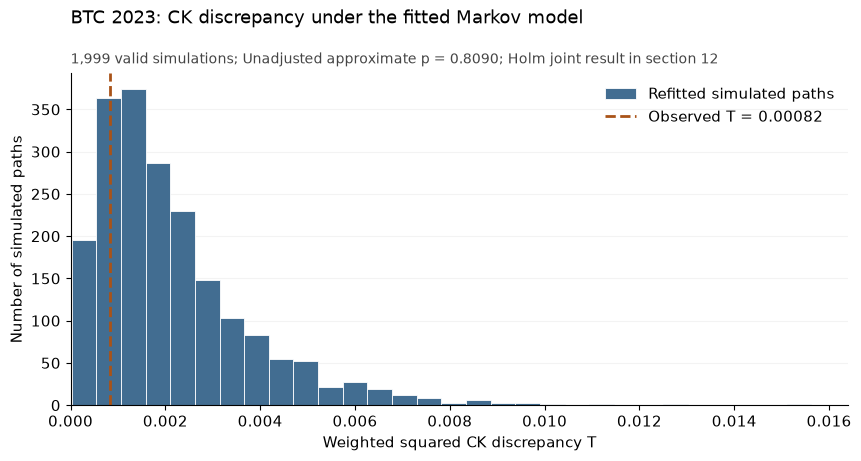

In [20]:
%matplotlib inline
import matplotlib.pyplot as plt

with plt.rc_context({"font.family": "DejaVu Sans", "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False}):
    fig, ax = plt.subplots(figsize=(8.5, 4.5), layout="constrained")
    if len(ck_valid):
        ax.hist(ck_valid, bins=30, color="#426D91", edgecolor="white",
                linewidth=0.6, label="Refitted simulated paths")
    ax.axvline(ck["statistic"], color="#A95318", linestyle="--", linewidth=2,
               label=f"Observed T = {ck['statistic']:.5f}")
    ax.set_xlim(left=0)
    ax.set_ylim(bottom=0)
    ax.set_xlabel("Weighted squared CK discrepancy T")
    ax.set_ylabel("Number of simulated paths")
    ax.set_title("BTC 2023: CK discrepancy under the fitted Markov model", loc="left", pad=36)
    p_text = (f"Unadjusted approximate p = {ck_result['p_value']:.4f}"
              if np.isfinite(ck_result["p_value"]) else "p withheld: invalid simulations")
    ax.text(0, 1.03, f"{len(ck_valid):,} valid simulations; {p_text}; Holm joint result in section 12",
            transform=ax.transAxes, fontsize=10, color="#454545")
    ax.legend(frameon=False, loc="upper right")
    ax.grid(axis="y", alpha=0.15)
    ax.set_axisbelow(True)
    display(fig)
    plt.close(fig)


### Interpretation and the second structural diagnostic

The CK discrepancy is **0.00082223**, with **1,617** out of 1,999 refitted
simulations at least as large and no invalid simulations: unadjusted
approximate p = **0.8090**. This is not an unusually large five-step discrepancy
under this calibration; it does not prove Markov behavior or predictive value.

Sections 11–12 complete the residence-time diagnostic and the planned joint
Holm calculation. These are development analyses of previously used data.
Rejection could reflect history dependence, time variation, or other
misspecification. Neither completion nor the results can change frozen Part A.


## 8. Prepare outcome labels for later rolling forecasts

This is the separate prediction workflow. Its causal labels feed the three rolling forecasters and common-cohort scoring below. It does not depend on CK or residence-time results.

For a non-risk origin date \(t\), define

\[
Y_t=\mathbf{1}\{\text{at least one of }S_{t+1},\ldots,S_{t+5}\text{ is }0\}.
\]

The label describes the realized outcome. It is not a probability forecast.
Require all five future daily states to be observed, even if an early hit is
already known. Keep missing labels as missing, not as zero. Starting in state 0
is outside the target population.

`shift(-k)` aligns the state k days ahead with today's row. This forward look
is intentional for constructing outcomes; it must never enter the predictors
at the same date. `target_end_date` is the last required observation date, not
the first-hit date. Before that date, the label is excluded from historical
frequency estimation.


In [21]:
def make_event_labels(states: pd.Series, horizon: int = 5) -> pd.DataFrame:
    """Build realized first-hit labels, retaining unavailable rows explicitly.

    A label requires a non-risk origin and all next h daily states. Its end
    date is always origin + h days, even when the first hit happens earlier.
    Historical estimation must additionally filter target_end_date <= as_of.
    """
    _validate_daily_index(states.index)
    if not states.dropna().isin([0, 1, 2]).all():
        raise ValueError("Observed states must be 0, 1, or 2.")
    if isinstance(horizon, (bool, np.bool_)) or not isinstance(horizon, (int, np.integer)) or horizon < 1:
        raise ValueError("The horizon must be a positive integer.")
    states = states.astype("Int64")

    # Negative shifts align FUTURE outcomes with their origin dates.
    # They are used only for labels, never as inputs to same-date predictions.
    future = pd.DataFrame({
        f"day_{k}": states.shift(-k) for k in range(1, int(horizon) + 1)
    })
    complete_future = future.notna().all(axis=1)
    available = states.isin([1, 2]) & complete_future
    target = pd.Series(pd.NA, index=states.index, dtype="Int64")
    target.loc[available] = future.eq(0).any(axis=1).loc[available].astype(int)

    status = pd.Series("incomplete_future", index=states.index, dtype="string")
    status.loc[states.isna()] = "origin_missing"
    status.loc[states.eq(0).fillna(False)] = "risk_origin"
    status.loc[available] = "available"
    return pd.DataFrame({
        "state": states,
        "target": target,
        "target_end_date": states.index + pd.Timedelta(days=int(horizon)),
        "label_status": status,
    })


In [22]:
labels = make_event_labels(features["state"], horizon=horizon)
display(labels.loc["2023-01-01":"2023-01-05"].style.format({
    "state": "{:.0f}", "target": "{:.0f}", "target_end_date": "{:%Y-%m-%d}",
}, na_rep="unavailable"))


,state,target,target_end_date,label_status
date,,,,
2023-01-01 00:00:00,1,0,2023-01-06,available
2023-01-02 00:00:00,1,0,2023-01-07,available
2023-01-03 00:00:00,1,0,2023-01-08,available
2023-01-04 00:00:00,1,0,2023-01-09,available
2023-01-05 00:00:00,1,0,2023-01-10,available


### Label coverage and the unfinished tail

The following counts account for every 2023 origin date. `available` means
the label can be computed by the end of the development file, not that it was
known on its origin date. The other statuses are mutually exclusive reasons
for exclusion; a risk origin is excluded regardless of future completeness.


In [23]:
labels_2023 = labels.loc[window_start:window_end]
status_order = ["available", "risk_origin", "origin_missing", "incomplete_future"]
label_counts = labels_2023["label_status"].value_counts().reindex(status_order, fill_value=0)
display(label_counts.rename("2023 origin dates").to_frame())


,2023 origin dates
label_status,
available,321
risk_origin,39
origin_missing,0
incomplete_future,5


In [24]:
display(labels_2023.tail(7).style.format({
    "state": "{:.0f}", "target": "{:.0f}", "target_end_date": "{:%Y-%m-%d}",
}, na_rep="unavailable"))


,state,target,target_end_date,label_status
date,,,,
2023-12-25 00:00:00,1,1,2023-12-30,available
2023-12-26 00:00:00,0,unavailable,2023-12-31,risk_origin
2023-12-27 00:00:00,1,unavailable,2024-01-01,incomplete_future
2023-12-28 00:00:00,1,unavailable,2024-01-02,incomplete_future
2023-12-29 00:00:00,1,unavailable,2024-01-03,incomplete_future
2023-12-30 00:00:00,1,unavailable,2024-01-04,incomplete_future
2023-12-31 00:00:00,1,unavailable,2024-01-05,incomplete_future


### Use only labels that have matured by an information cutoff

This illustration uses information available after the January 1, 2023 daily
bar completes. Under the draft rolling rule, the historical origin window is
January 2, 2022 through January 1, 2023. A historical five-day outcome can be
used only if its end date is January 1, 2023 or earlier. Thus its latest
possible origin date is December 27, 2022.

This is an example cutoff, not a permanent parameter-freeze date. In a rolling
forecast, it advances each day. The full-year 2023 matrix above remains a
descriptive calculation and will not be used to score earlier predictions.


In [25]:
as_of = pd.Timestamp("2023-01-01")
history_start = as_of - pd.Timedelta(days=364)
mature_history = labels.loc[
    (labels.index >= history_start)
    & (labels.index <= as_of)
    & labels["target"].notna()
    & (labels["target_end_date"] <= as_of)
]
display(pd.Series({
    "Information cutoff": as_of.date(),
    "Historical origin window starts": history_start.date(),
    "Latest possible mature origin": (as_of - pd.Timedelta(days=horizon)).date(),
    "Available historical labels": len(mature_history),
    "Latest retained origin": mature_history.index.max().date(),
    "Latest retained outcome date": mature_history["target_end_date"].max().date(),
}, name="Maturity filter example").to_frame())


,Maturity filter example
Information cutoff,2023-01-01
Historical origin window starts,2022-01-02
Latest possible mature origin,2022-12-27
Available historical labels,312
Latest retained origin,2022-12-27
Latest retained outcome date,2023-01-01


## Checks for the descriptive and label modules

These checks cover development data only. The Part A rolling replay follows below; it does not use the full-year descriptive matrix as an earlier forecast.

In [26]:
assert len(window_states) == 365 and window_states.notna().all()
assert counts.sum() == 364
np.testing.assert_allclose(P.sum(axis=1), 1)
assert hit.between(0, 1).all()
assert np.all(hit.to_numpy() >= endpoint - 1e-12)
assert hashlib.sha256(csv_path.read_bytes()).hexdigest() == source_sha256
assert label_counts.sum() == 365
assert labels["target"].dropna().isin([0, 1]).all()
assert labels["target"].notna().equals(labels["label_status"].eq("available").astype(bool))
assert labels["target"].iloc[-horizon:].isna().all()
assert (labels["target_end_date"] == labels.index + pd.Timedelta(days=horizon)).all()
assert labels.loc[labels["state"].eq(0).fillna(False), "target"].isna().all()
assert mature_history["target_end_date"].le(as_of).all()
assert (mature_history.index >= history_start).all()
print("Development input, matrix, and event-label checks passed.")
print("Source:", csv_path.relative_to(ROOT))
print("SHA256:", source_sha256)
print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__, "pandas:", pd.__version__)

assert ck["counts_lag"].sum() == len(window_states) - horizon
np.testing.assert_allclose(ck["P1"], P)
assert 0 <= ck["statistic"] <= 2 + 1e-12
assert len(ck_result["simulated_statistics"]) == 1999
if ck_result["invalid_simulations"] == 0:
    assert 0 < ck_result["p_value"] <= 1
else:
    assert np.isnan(ck_result["p_value"])
print("CK counts, statistic, and simulation checks passed.")
print("Matplotlib:", plt.matplotlib.__version__)


Development input, matrix, and event-label checks passed.
Source: data/development/BTCUSDT_1d_2020-01_2023-12.csv
SHA256: 64ae4f3a75f61e216c36a7cb41eacaeb645ce3c27b6fd1e4ad3da9c87ef957f5
Python: 3.12.14
NumPy: 2.3.5 pandas: 2.2.3
CK counts, statistic, and simulation checks passed.
Matplotlib: 3.11.2


## 9. Three causal rolling forecasters — Part A

At each origin, the history window is `[t - 364 days, t]`: at most 364 adjacent pairs. Add one to every transition cell before row normalization. Use only fully matured five-day labels for both Beta(1,1) frequency baselines. Both non-risk groups must satisfy the declared minimum sample sizes. Predictions never require the origin’s future label.

The one-year window is a fixed development choice, not an empirically proven optimum. Earlier 2023 work informed this design; the replay below is development validation, not an untouched test.


In [27]:
import json
part_a_config = json.loads((ROOT / "research/part_a_config.json").read_text())
display(pd.Series({key: str(value) for key, value in part_a_config.items()}, name="Fixed Part A configuration").to_frame())

,Fixed Part A configuration
horizon,5
window_days,365
dirichlet_alpha,1
beta_alpha,1
beta_beta,1
min_pairs,250
min_source_pairs,20
min_labels,100
min_state_labels,20
log_clip,1e-12


In [28]:
def _validate_prediction_config(config):
    """Validate numerical controls; the gate additionally locks their values."""
    for key in ("horizon", "window_days", "min_pairs", "min_source_pairs",
                "min_labels", "min_state_labels", "calibration_bins", "bootstrap_samples"):
        value = config[key]
        if isinstance(value, (bool, np.bool_)) or not isinstance(value, (int, np.integer)) or value < 1:
            raise ValueError(f"{key} must be a positive integer.")
    if config["window_days"] <= config["horizon"]:
        raise ValueError("The history window must exceed the forecast horizon.")
    for key in ("dirichlet_alpha", "beta_alpha", "beta_beta", "bootstrap_mean_block"):
        if not np.isfinite(config[key]) or config[key] <= 0:
            raise ValueError(f"{key} must be positive and finite.")
    if config["bootstrap_mean_block"] < 1:
        raise ValueError("The mean calendar-block length must be at least one.")
    if not 0 < config["log_clip"] < 0.5 or not 0 < config["ci_level"] < 1:
        raise ValueError("Invalid log-loss clipping or confidence level.")
    seed = config["bootstrap_seed"]
    if isinstance(seed, (bool, np.bool_)) or not isinstance(seed, (int, np.integer)) or seed < 0:
        raise ValueError("The bootstrap seed must be a nonnegative integer.")

In [29]:
def smoothed_transition_matrix(counts, alpha=1.0):
    """Dirichlet posterior mean: add alpha to each destination count."""
    counts = np.asarray(counts, dtype=float)
    if (counts.shape != (3, 3) or not np.isfinite(counts).all()
            or (counts < 0).any() or not np.equal(counts, np.floor(counts)).all()):
        raise ValueError("Counts must be a finite nonnegative 3-by-3 integer matrix.")
    if not np.isfinite(alpha) or alpha <= 0:
        raise ValueError("The Dirichlet pseudocount must be positive and finite.")
    return (counts + alpha) / (counts.sum(axis=1, keepdims=True) + 3 * alpha)

In [30]:
def historical_frequency_baselines(states, as_of, config):
    """Use only full labels matured by as_of, with origins in its history window.

    Truncate the path BEFORE constructing labels. An early observed hit cannot
    qualify an otherwise unfinished five-day window. Both groups are returned,
    even when the current state belongs to just one group.
    """
    _validate_prediction_config(config)
    _validate_daily_index(states.index)
    as_of = pd.Timestamp(as_of)
    if as_of not in states.index:
        raise ValueError("The information date must be an observed calendar date.")
    history_start = as_of - pd.Timedelta(days=config["window_days"] - 1)
    history = states.loc[history_start:as_of]
    labels = make_event_labels(history, horizon=config["horizon"])
    mature = labels.loc[labels["target"].notna() & labels["target_end_date"].le(as_of)]
    a, b = config["beta_alpha"], config["beta_beta"]
    result = {"n_labels": len(mature), "hits": int(mature["target"].sum()),
              "latest_label_origin": mature.index.max(),
              "latest_label_end": mature["target_end_date"].max()}
    result["q_pooled"] = (result["hits"] + a) / (result["n_labels"] + a + b)
    for state in (1, 2):
        group = mature.loc[mature["state"].eq(state)]
        result[f"n_labels_{state}"] = len(group)
        result[f"hits_{state}"] = int(group["target"].sum())
        result[f"q_state_{state}"] = (int(group["target"].sum()) + a) / (len(group) + a + b)
    return result

In [31]:
def rolling_forecasts(states, start, end, config):
    """Three forecasts from the same daily information set and shared mask.

    Outcomes for the forecast being made are neither accepted nor needed here.
    Non-risk eligibility requires BOTH non-risk source/label groups to meet
    their thresholds. Excluded dates remain in the daily calendar with NaN q.
    """
    _validate_prediction_config(config)
    _validate_daily_index(states.index)
    if not states.dropna().isin([0, 1, 2]).all():
        raise ValueError("Observed states must be 0, 1, or 2.")
    start, end = pd.Timestamp(start), pd.Timestamp(end)
    if start not in states.index or end not in states.index or start > end:
        raise ValueError("Forecast bounds must be ordered dates in the state calendar.")
    rows = []
    for today in states.loc[start:end].index:
        history_start = today - pd.Timedelta(days=config["window_days"] - 1)
        history = states.loc[history_start:today]
        counts = count_transitions(history)
        source_counts = counts.sum(axis=1)
        frequencies = historical_frequency_baselines(history, today, config)
        current = states.at[today]
        reasons = []
        if pd.isna(current):
            reasons.append("origin_missing")
        elif current == 0:
            reasons.append("risk_origin")
        if counts.sum() < config["min_pairs"]:
            reasons.append("insufficient_pairs")
        for state in (1, 2):
            if source_counts[state] < config["min_source_pairs"]:
                reasons.append(f"insufficient_source_{state}")
        if frequencies["n_labels"] < config["min_labels"]:
            reasons.append("insufficient_labels")
        for state in (1, 2):
            if frequencies[f"n_labels_{state}"] < config["min_state_labels"]:
                reasons.append(f"insufficient_labels_{state}")
        row = {
            "date": today, "state": current, "history_start": history_start,
            "n_pairs": int(counts.sum()), "n_source_1": int(source_counts[1]),
            "n_source_2": int(source_counts[2]),
            **{key: frequencies[key] for key in ("n_labels", "n_labels_1", "n_labels_2",
                                                "latest_label_origin", "latest_label_end")},
            "eligible": not reasons, "exclusion_reason": "|".join(reasons),
            "q_markov": np.nan, "q_pooled": np.nan, "q_state": np.nan,
        }
        if not reasons:
            P_today = smoothed_transition_matrix(counts, config["dirichlet_alpha"])
            row["q_markov"] = float(first_passage_probabilities(P_today, config["horizon"]).loc[int(current)])
            row["q_pooled"] = float(frequencies["q_pooled"])
            row["q_state"] = float(frequencies[f"q_state_{int(current)}"])
        rows.append(row)
    result = pd.DataFrame(rows).set_index("date")
    result["state"] = result["state"].astype("Int64")
    return result

### Replay a real information date

The January 1, 2023 forecast uses the history starting January 2, 2022. The latest permissible historical label origin is December 27, 2022. The current forecast’s January 2–6 outcome is not used to estimate any probability. All three forecasts are withheld together if any eligibility rule fails.

In [32]:
first_forecast = rolling_forecasts(features["state"], "2023-01-01", "2023-01-01", part_a_config)
display(first_forecast.T)

date,2023-01-01
state,1
history_start,2022-01-02 00:00:00
n_pairs,364
n_source_1,276
n_source_2,40
n_labels,312
n_labels_1,272
n_labels_2,40
latest_label_origin,2022-12-27 00:00:00
latest_label_end,2023-01-01 00:00:00


## 10. Score the same origins and preserve calendar dependence — Part A

Brier loss uses the original probabilities; log loss alone uses clipping at `1e-12`. Calibration uses ten fixed equal-width bins, with 1 included in the last bin. The primary contrast is direct-state Brier loss minus Markov Brier loss. Positive differences favor Markov.

The stationary bootstrap uses 2,000 paired draws over the entire origin calendar, mean block length 10 days, seed 20261007. Ineligible dates remain missing calendar positions. Each draw is shared by all models; models are not refitted. Report a 95% percentile interval. If any draw has no scorable dates, retain it and withhold intervals. Improvement is supported only when the primary interval’s lower endpoint exceeds zero.


In [33]:
def stationary_bootstrap_indices(n, n_resamples, mean_block, seed):
    """Paired circular stationary-bootstrap indices on the FULL daily calendar.

    Start uniformly. At each following position, restart at a uniform date
    with probability 1/mean_block; otherwise advance one calendar day with
    wraparound. Every resample has the same number of calendar positions.
    """
    for name, value, minimum in (("n", n, 1), ("n_resamples", n_resamples, 1), ("seed", seed, 0)):
        if isinstance(value, (bool, np.bool_)) or not isinstance(value, (int, np.integer)) or value < minimum:
            raise ValueError(f"{name} must be an integer at least {minimum}.")
    if not np.isfinite(mean_block) or mean_block < 1:
        raise ValueError("The mean block length must be finite and at least one.")
    rng = np.random.default_rng(seed)
    indices = np.empty((n_resamples, n), dtype=int)
    indices[:, 0] = rng.integers(0, n, size=n_resamples)
    for position in range(1, n):
        restart = rng.random(n_resamples) < 1 / mean_block
        starts = rng.integers(0, n, size=n_resamples)
        indices[:, position] = np.where(restart, starts, (indices[:, position - 1] + 1) % n)
    return indices

In [34]:
def score_forecasts(forecasts, labels, config):
    """Score a common realized cohort; preserve calendar holes in inference.

    Brier uses original probabilities. Only log loss clips probabilities.
    Bootstrap intervals condition on the generated forecast paths; models
    are not re-estimated in resamples. All three contrasts share each draw.
    """
    _validate_prediction_config(config)
    _validate_daily_index(forecasts.index)
    _validate_daily_index(labels.index)
    if len(forecasts) == 0 or not forecasts.index.isin(labels.index).all():
        raise ValueError("All forecast dates require corresponding label rows.")
    aligned = labels.loc[forecasts.index]
    if not aligned["target"].dropna().isin([0, 1]).all():
        raise ValueError("Observed targets must be binary.")
    if not aligned["target_end_date"].eq(aligned.index + pd.Timedelta(days=config["horizon"])).all():
        raise ValueError("Labels must use the complete declared horizon.")
    if not aligned["state"].astype("Int64").equals(forecasts["state"].astype("Int64")):
        raise ValueError("Forecast and label origin states must agree.")
    if aligned.loc[aligned["target"].notna(), "state"].isin([1, 2]).eq(False).any():
        raise ValueError("A realized target requires a non-risk origin.")
    if forecasts["eligible"].isna().any() or not forecasts["eligible"].isin([True, False]).all():
        raise ValueError("Forecast eligibility must be boolean.")
    eligible = forecasts["eligible"].astype(bool)
    models = ("markov", "pooled", "state")
    probabilities = forecasts[[f"q_{m}" for m in models]].astype(float)
    values = probabilities.loc[eligible].to_numpy()
    if not np.isfinite(values).all() or (values < 0).any() or (values > 1).any():
        raise ValueError("Every eligible origin requires three finite probabilities in [0, 1].")
    if not forecasts.loc[eligible, "state"].isin([1, 2]).all():
        raise ValueError("Only non-risk origins may be eligible.")
    scorable = eligible & aligned["target"].notna()
    y = aligned["target"].astype(float)
    daily = pd.DataFrame({"target": aligned["target"], "scorable": scorable}, index=forecasts.index)
    daily["score_exclusion_reason"] = np.where(
        ~eligible, "forecast:" + forecasts["exclusion_reason"].fillna(""),
        np.where(aligned["target"].isna(), "label_unavailable", ""))
    summaries, calibration = [], []
    for model in models:
        q = probabilities[f"q_{model}"]
        clipped = q.clip(config["log_clip"], 1 - config["log_clip"])
        daily[f"brier_{model}"] = ((q - y) ** 2).where(scorable)
        daily[f"log_{model}"] = (-(y * np.log(clipped) + (1 - y) * np.log1p(-clipped))).where(scorable)
        summaries.append({"model": model, "n": int(scorable.sum()),
                          "brier": daily[f"brier_{model}"].mean(),
                          "log_loss": daily[f"log_{model}"].mean(),
                          "event_rate": y.loc[scorable].mean(),
                          "mean_forecast": q.loc[scorable].mean()})
        bins = config["calibration_bins"]
        for k in range(bins):
            lower, upper = k / bins, (k + 1) / bins
            member = scorable & q.ge(lower) & (q.lt(upper) if k < bins - 1 else q.le(upper))
            calibration.append({"model": model, "bin": k, "lower": lower, "upper": upper,
                                "n": int(member.sum()), "mean_forecast": q.loc[member].mean(),
                                "event_rate": y.loc[member].mean()})
    pairs = {"markov_vs_state": ("markov", "state"),
             "markov_vs_pooled": ("markov", "pooled"),
             "state_vs_pooled": ("state", "pooled")}
    differences = pd.DataFrame({name: daily[f"brier_{baseline}"] - daily[f"brier_{model}"]
                                for name, (model, baseline) in pairs.items()})
    indices = stationary_bootstrap_indices(len(daily), config["bootstrap_samples"],
                                           config["bootstrap_mean_block"], config["bootstrap_seed"])
    sampled = differences.to_numpy()[indices]
    denominators = np.isfinite(sampled[:, :, 0]).sum(axis=1)
    invalid = int((denominators == 0).sum())
    boot = np.full((len(indices), len(pairs)), np.nan)
    np.divide(np.nansum(sampled, axis=1), denominators[:, None], out=boot,
              where=denominators[:, None] > 0)
    bootstrap = pd.DataFrame(boot, columns=list(pairs))
    bootstrap.index.name = "resample"
    comparisons = []
    tail = (1 - config["ci_level"]) / 2
    for column, name in enumerate(pairs):
        lower, upper = (np.nan, np.nan) if invalid else np.quantile(boot[:, column], [tail, 1 - tail])
        decision = ("unavailable" if invalid else "supports_improvement" if lower > 0
                    else "supports_worse" if upper < 0 else "uncertain")
        comparisons.append({"comparison": name, "delta_brier": differences[name].mean(),
                            "ci_lower": lower, "ci_upper": upper, "n": int(scorable.sum()),
                            "invalid_resamples": invalid, "decision": decision})
    coverage = pd.DataFrame([{"calendar_origins": len(daily), "forecast_eligible": int(eligible.sum()),
                              "scorable": int(scorable.sum()), "forecast_excluded": int((~eligible).sum()),
                              "label_unavailable": int((eligible & aligned["target"].isna()).sum())}])
    return {"daily_losses": daily, "summary": pd.DataFrame(summaries).set_index("model"),
            "calibration": pd.DataFrame(calibration),
            "comparisons": pd.DataFrame(comparisons).set_index("comparison"),
            "coverage": coverage, "bootstrap": bootstrap}

In [35]:
def evaluate_asset(close, origin_start, origin_end, config):
    """Run the fixed pipeline on an explicitly authorized input series.

    This pure calculation does not open files. The CLI evaluation gate alone
    authorizes loading holdout prices; notebook examples use development only.
    """
    features_for_run = make_features(close)
    states_for_run = features_for_run["state"]
    forecasts_for_run = rolling_forecasts(states_for_run, origin_start, origin_end, config)
    labels_for_run = make_event_labels(states_for_run, config["horizon"])
    scores = score_forecasts(forecasts_for_run, labels_for_run, config)
    return {"forecasts": forecasts_for_run, "labels": labels_for_run.loc[forecasts_for_run.index], **scores}

### Development replay: BTC, 2023

Evaluate origins January 1–December 26, with five-day labels matured by December 31. Pre-2023 history is available for causal estimation. These already-used development observations test implementation and help explain behavior; they do not supply a new out-of-sample claim. No parameter will be selected from this replay.

In [36]:
development_result = evaluate_asset(btc["close"], "2023-01-01", "2023-12-26", part_a_config)
display(development_result["summary"].style.format({"n":"{:.0f}", "brier":"{:.6f}", "log_loss":"{:.6f}", "event_rate":"{:.2%}", "mean_forecast":"{:.2%}"}))
display(development_result["coverage"])

,n,brier,log_loss,event_rate,mean_forecast
model,,,,,
markov,321,0.253410,0.700223,45.48%,42.18%
pooled,321,0.255005,0.703592,45.48%,41.49%
state,321,0.255398,0.704392,45.48%,41.65%


,calendar_origins,forecast_eligible,scorable,forecast_excluded,label_unavailable
0,360,321,321,39,0


In [37]:
display(development_result["comparisons"].style.format({"delta_brier":"{:+.6f}", "ci_lower":"{:+.6f}", "ci_upper":"{:+.6f}", "n":"{:.0f}", "invalid_resamples":"{:.0f}"}))
display(development_result["forecasts"]["exclusion_reason"].replace("", "eligible").value_counts().rename("Calendar origins").to_frame())

,delta_brier,ci_lower,ci_upper,n,invalid_resamples,decision
comparison,,,,,,
markov_vs_state,+0.001988,-0.003013,+0.007037,321,0,uncertain
markov_vs_pooled,+0.001596,-0.003967,+0.007086,321,0,uncertain
state_vs_pooled,-0.000393,-0.001847,+0.001187,321,0,uncertain


,Calendar origins
exclusion_reason,
eligible,321
risk_origin,39


In [38]:
display(development_result["calibration"].style.format({"lower":"{:.1f}", "upper":"{:.1f}", "n":"{:.0f}", "mean_forecast":"{:.2%}", "event_rate":"{:.2%}"}, na_rep="unavailable"))

,model,bin,lower,upper,n,mean_forecast,event_rate
0,markov,0,0.0,0.1,0,unavailable,unavailable
1,markov,1,0.1,0.2,0,unavailable,unavailable
2,markov,2,0.2,0.3,0,unavailable,unavailable
3,markov,3,0.3,0.4,113,38.57%,42.48%
4,markov,4,0.4,0.5,197,43.78%,48.73%
5,markov,5,0.5,0.6,11,50.54%,18.18%
6,markov,6,0.6,0.7,0,unavailable,unavailable
7,markov,7,0.7,0.8,0,unavailable,unavailable
8,markov,8,0.8,0.9,0,unavailable,unavailable
9,markov,9,0.9,1.0,0,unavailable,unavailable


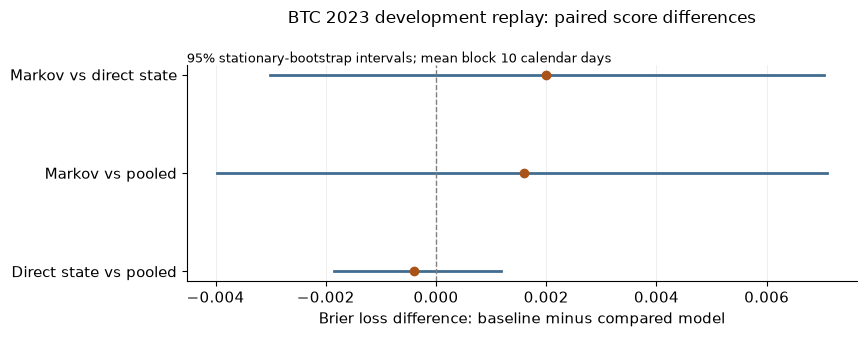

In [39]:
with plt.rc_context({"font.family":"DejaVu Sans", "font.size":11, "axes.spines.top":False, "axes.spines.right":False}):
    fig, ax = plt.subplots(figsize=(8.8, 3.5))
    comparison = development_result["comparisons"]
    names = ["Markov vs direct state", "Markov vs pooled", "Direct state vs pooled"]
    for row, (name, values) in enumerate(comparison.iterrows()):
        if np.isfinite(values["ci_lower"]):
            ax.plot([values["ci_lower"], values["ci_upper"]], [row, row], color="#426D91", linewidth=2)
        ax.plot(values["delta_brier"], row, "o", color="#A95318")
    ax.axvline(0, color="0.5", linestyle="--", linewidth=1)
    ax.set_yticks(range(3), names)
    ax.invert_yaxis()
    ax.set_xlabel("Brier loss difference: baseline minus compared model")
    ax.set_title("BTC 2023 development replay: paired score differences", pad=30, fontsize=12)
    ax.text(0, 1.01, "95% stationary-bootstrap intervals; mean block 10 calendar days", transform=ax.transAxes, fontsize=9)
    ax.grid(axis="x", alpha=.2)
    fig.tight_layout()
    display(fig)
    plt.close(fig)

### Reading the replay and the freeze boundary

The primary development difference is +0.001988 Brier units in favor of Markov, but its 95% interval [-0.003013, +0.007037] includes zero. The result is uncertain under the declared rule. All three pairwise intervals include zero. These scores and intervals are development results. CK and residence-time results do not determine which predictor, window, threshold, or score is used. Only the gated, single holdout evaluation can support the prespecified new-sample primary claim.

On October 7, timestamp/checksum-only availability checks lock a shared final month for all three assets. If any September archive is unavailable, use outcomes through August 31 and origins through August 26, and state this in the report. Invalid checksums or calendar gaps block evaluation rather than selecting another interval.

Core Part A function cells are tagged `part-a-functions`. The gate verifies their frozen projection plus the protected protocol, configuration, code, tests, and runtime requirements. Part B notebook explanations and diagnostic functions can continue changing without altering that projection.


In [40]:
assert development_result["summary"]["n"].nunique() == 1
assert development_result["coverage"].iloc[0][["scorable", "forecast_excluded", "label_unavailable"]].sum() == 360
assert development_result["forecasts"]["latest_label_end"].le(development_result["forecasts"].index).all()
assert development_result["labels"]["target_end_date"].max() == pd.Timestamp("2023-12-31")
print("Part A development replay completed without reading holdout prices.")

Part A development replay completed without reading holdout prices.


## 11. Part B: residence times in the fixed 2023 window

For a homogeneous Markov chain, a run starting on entry into state $i$ has
$\Pr(L_i\geq\ell)=P_{ii}^{\ell-1}$. We test a specific implication, not the
entire Markov property. The window and raw transition estimator match section 7.

**Prespecified before this residence calculation:** discard the first and last
runs because entry or exit is outside the window. Require at least five complete
runs in each state. Use the fixed duration grid $\ell=2,\ldots,20$ and weights
$w_i=m_i/\sum_jm_j$, where $m_i$ counts complete runs. The statistic is

$$T_R=\sum_i w_i\frac{1}{19}\sum_{\ell=2}^{20}
\left[\frac{\#\{\text{complete runs of }i\text{ with length}\geq\ell\}}{m_i}
-\widehat P_{ii}^{\ell-1}\right]^2.$$

The grid and five-run minimum are pragmatic fixed development choices, not
optimized cutoffs or a guarantee of power. This statistic weights rare states
less and cannot locate discrepancies specifically beyond duration 20.

Removing boundary runs favors shorter runs. Therefore the geometric curve is
a **population model reference**, not the exact finite-window expectation of
this selected sample. Simulations repeat the same selection and refitting.
The specification was designed on previously used development data; this is
not independent preregistration. See `research/protocol_part_b.md`.

In [41]:
import json
part_b_config = json.loads((ROOT / "research/part_b_config.json").read_text())
assert part_b_config["development_end"] == "2023-12-31"
display(pd.Series({k: v for k, v in part_b_config.items() if k != "windows"}, name="Part B setting"))
display(pd.DataFrame(part_b_config["windows"]))

asset                 BTCUSDT
development_end    2023-12-31
ck_lag                      5
max_duration               20
min_runs                    5
n_simulations            1999
seed                 20261004
alpha                    0.05
Name: Part B setting, dtype: object

,name,start,end,family
0,2023,2023-01-01,2023-12-31,primary
1,2020,2020-01-22,2020-12-31,exploratory
2,2021,2021-01-01,2021-12-31,exploratory
3,2022,2022-01-01,2022-12-31,exploratory
4,pooled_2020_2023,2020-01-22,2023-12-31,exploratory


### 11.1 Extract runs and mark the boundaries

Transitions used to fit $P$ include all observed adjacent pairs, including
pairs within boundary runs. Only the empirical run distribution excludes the
first and last runs. A path containing one or two runs has no complete runs.

In [42]:
def extract_complete_runs(states: pd.Series) -> pd.DataFrame:
    """List every run, marking the first and last as boundary-truncated."""
    _validate_daily_index(states.index)
    if len(states) == 0 or states.isna().any() or not states.isin([0, 1, 2]).all():
        raise ValueError("Residence times require a nonempty complete daily state path.")
    values = states.to_numpy(dtype=int)
    starts = np.r_[0, np.flatnonzero(values[1:] != values[:-1]) + 1]
    ends = np.r_[starts[1:], len(values)]  # Exclusive end positions.
    run_number = np.arange(len(starts))
    return pd.DataFrame({
        "state": values[starts], "length": ends - starts,
        "start_date": states.index[starts], "end_date": states.index[ends - 1],
        "left_truncated": run_number == 0,
        "right_truncated": run_number == len(starts) - 1,
        "complete": (run_number > 0) & (run_number < len(starts) - 1),
    })


def development_window(states: pd.Series, start: str, end: str) -> pd.Series:
    """Select a fixed complete daily window strictly within development years."""
    first, last = pd.Timestamp(start), pd.Timestamp(end)
    if pd.isna(first) or pd.isna(last) or not pd.Timestamp("2020-01-01") <= first <= last <= pd.Timestamp("2023-12-31"):
        raise ValueError("Part B windows must lie within 2020-2023.")
    selected = states.loc[first:last]
    expected = pd.date_range(first, last, freq="D")
    if not selected.index.equals(expected) or selected.isna().any() or not selected.isin([0, 1, 2]).all():
        raise ValueError("The complete prespecified development window is required.")
    return selected


In [43]:
primary_window_spec = next(item for item in part_b_config["windows"] if item["name"] == "2023")
residence_runs = pd.DataFrame(columns=["state", "length", "start_date", "end_date",
                                     "left_truncated", "right_truncated", "complete"])
try:
    residence_path = development_window(features["state"], primary_window_spec["start"], primary_window_spec["end"])
except ValueError as error:
    if str(error) != "The complete prespecified development window is required.":
        raise
    display(pd.DataFrame([{"status": "unavailable", "reason": str(error)}]))
else:
    residence_runs = extract_complete_runs(residence_path)
    display(residence_runs.head(8))
    display(residence_runs.tail(3))


,state,length,start_date,end_date,left_truncated,right_truncated,complete
0,1,7,2023-01-01,2023-01-07,True,False,False
1,2,1,2023-01-08,2023-01-08,False,False,True
2,1,1,2023-01-09,2023-01-09,False,False,True
3,2,5,2023-01-10,2023-01-14,False,False,True
4,1,3,2023-01-15,2023-01-17,False,False,True
5,0,1,2023-01-18,2023-01-18,False,False,True
6,1,1,2023-01-19,2023-01-19,False,False,True
7,2,1,2023-01-20,2023-01-20,False,False,True


,state,length,start_date,end_date,left_truncated,right_truncated,complete
123,1,5,2023-12-21,2023-12-25,False,False,True
124,0,1,2023-12-26,2023-12-26,False,False,True
125,1,5,2023-12-27,2023-12-31,False,True,False


### 11.2 Compute one discrepancy, then calibrate it by simulation

Fit the raw matrix using all adjacent pairs. For each of 1,999 simulations,
fix the observed initial state and path length, refit $P$, extract runs, and
recompute the weights and discrepancy. Use the same seed as CK; Holm does not
require the two p-values to be independent. This remains an approximate
parametric-bootstrap calibration of a composite null.

If any simulated path has an empty transition row or fewer than five complete
runs in any state, retain it as invalid and withhold the p-value. Do not redraw
or silently omit it. Missing dates or states make an observed path unavailable.

In [44]:
def residence_statistic(states: pd.Series, max_duration: int = 20,
                        min_runs: int = 5) -> dict:
    """Weighted squared discrepancy from geometric survival on a fixed grid.

    Interior runs are window-selected; the geometric curve is a population
    model reference, not the exact finite-window mean of the selected runs.
    Calibration must reproduce this selection and refit P for every path.
    """
    for name, value, minimum in [("max_duration", max_duration, 2), ("min_runs", min_runs, 1)]:
        if isinstance(value, (bool, np.bool_)) or not isinstance(value, (int, np.integer)) or value < minimum:
            raise ValueError(f"{name} must be an integer at least {minimum}.")
    runs = extract_complete_runs(states)
    counts_1 = count_transitions(states)
    P1 = estimate_transition_matrix(counts_1)
    complete = runs.loc[runs["complete"]]
    run_counts = np.array([(complete["state"] == i).sum() for i in range(3)], dtype=int)
    if (run_counts < min_runs).any():
        raise ValueError("Too few complete runs in at least one state.")
    durations = np.arange(2, max_duration + 1)
    empirical = np.array([
        (complete.loc[complete["state"] == i, "length"].to_numpy()[:, None]
         >= durations[None, :]).mean(axis=0) for i in range(3)
    ])
    geometric = np.diag(P1)[:, None] ** (durations[None, :] - 1)
    weights = run_counts / run_counts.sum()
    statistic = float(weights @ ((empirical - geometric) ** 2).mean(axis=1))
    return {
        "P1": P1, "counts_1": counts_1, "runs": runs,
        "run_counts": run_counts, "run_weights": weights, "durations": durations,
        "empirical_survival": empirical, "geometric_survival": geometric,
        "statistic": statistic,
    }

In [45]:
def residence_bootstrap(states: pd.Series, max_duration: int = 20, min_runs: int = 5,
                        n_simulations: int = 1999, seed: int = 20261004) -> dict:
    """Calibrate by refitting each simulated path; retain every invalid draw."""
    observed = residence_statistic(states, max_duration=max_duration, min_runs=min_runs)
    paths = simulate_markov_paths(observed["P1"], int(states.iloc[0]),
                                  len(states), n_simulations, seed=seed)
    simulated_statistics = np.full(n_simulations, np.nan)
    invalid_reason_counts = {}
    sparse_errors = {
        "Raw transition probabilities are undefined for an empty source row.",
        "Too few complete runs in at least one state.",
    }
    for b, path in enumerate(paths):
        simulated = pd.Series(path, index=states.index, dtype="Int64")
        try:
            result = residence_statistic(simulated, max_duration=max_duration, min_runs=min_runs)
        except ValueError as error:
            reason = str(error)
            if reason not in sparse_errors:
                raise  # Do not hide input errors or implementation failures.
            invalid_reason_counts[reason] = invalid_reason_counts.get(reason, 0) + 1
            continue
        simulated_statistics[b] = result["statistic"]
    invalid = int(np.isnan(simulated_statistics).sum())
    exceedances = None if invalid else int((simulated_statistics >= observed["statistic"]).sum())
    p_value = np.nan if invalid else (1 + exceedances) / (n_simulations + 1)
    return {
        "observed": observed, "simulated_statistics": simulated_statistics,
        "p_value": p_value, "invalid_simulations": invalid,
        "invalid_reason_counts": invalid_reason_counts,
        "n_simulations": int(n_simulations), "exceedances": exceedances, "seed": int(seed),
    }


def run_development_diagnostic(states: pd.Series, start: str, end: str,
                               diagnostic: str, config: dict) -> dict:
    """Retain expected observed unavailability; propagate other failures."""
    if diagnostic not in {"CK", "Residence"}:
        raise ValueError("Unknown development diagnostic.")
    expected_unavailable = {
        "The complete prespecified development window is required.",
        "Raw transition probabilities are undefined for an empty source row.",
        "Too few complete runs in at least one state.",
    }
    try:
        path = development_window(states, start, end)
        if diagnostic == "CK":
            return ck_bootstrap(path, lag=config["ck_lag"],
                                n_simulations=config["n_simulations"], seed=config["seed"])
        return residence_bootstrap(path, max_duration=config["max_duration"],
            min_runs=config["min_runs"], n_simulations=config["n_simulations"], seed=config["seed"])
    except ValueError as error:
        if str(error) not in expected_unavailable:
            raise
        return {"observed": None, "p_value": np.nan, "invalid_simulations": None,
                "n_simulations": 0, "exceedances": None,
                "simulated_statistics": np.array([], dtype=float),
                "invalid_reason_counts": {}, "unavailable_reason": str(error)}


In [46]:
residence_result = run_development_diagnostic(
    features["state"], primary_window_spec["start"], primary_window_spec["end"],
    "Residence", part_b_config,
)
residence = residence_result["observed"]
run_summary = pd.DataFrame()
if residence is None:
    display(pd.DataFrame([{"status": "unavailable", "reason": residence_result["unavailable_reason"],
                           "simulations": 0, "unadjusted_p": np.nan}]))
else:
    run_summary = pd.DataFrame({
        "complete_runs": residence["run_counts"], "run_weight": residence["run_weights"],
        "fitted_P_ii": np.diag(residence["P1"]),
        "mean_complete_length": [residence_runs.loc[residence_runs["complete"] & residence_runs["state"].eq(i), "length"].mean() for i in range(3)],
        "geometric_population_mean": 1 / (1 - np.diag(residence["P1"])),
    }, index=pd.Index(range(3), name="state"))
    display(run_summary.round(6))
    display(pd.DataFrame([{
        "statistic": residence["statistic"], "unadjusted_p": residence_result["p_value"],
        "exceedances": residence_result["exceedances"],
        "invalid_simulations": residence_result["invalid_simulations"],
        "simulations": residence_result["n_simulations"],
    }]))

,complete_runs,run_weight,fitted_P_ii,mean_complete_length,geometric_population_mean
state,,,,,
0,34,0.274194,0.128205,1.147059,1.147059
1,54,0.435484,0.804965,5.018519,5.127273
2,36,0.290323,0.162791,1.194444,1.194444


,statistic,unadjusted_p,exceedances,invalid_simulations,simulations
0,0.00056,0.328,655,0,1999


### 11.3 Compare empirical survival with the model reference

These curves are descriptive. The test uses the refitted simulation distribution,
not a visual threshold or the assumption that complete runs are an unbiased
geometric sample. The means above have the same boundary-selection caveat.

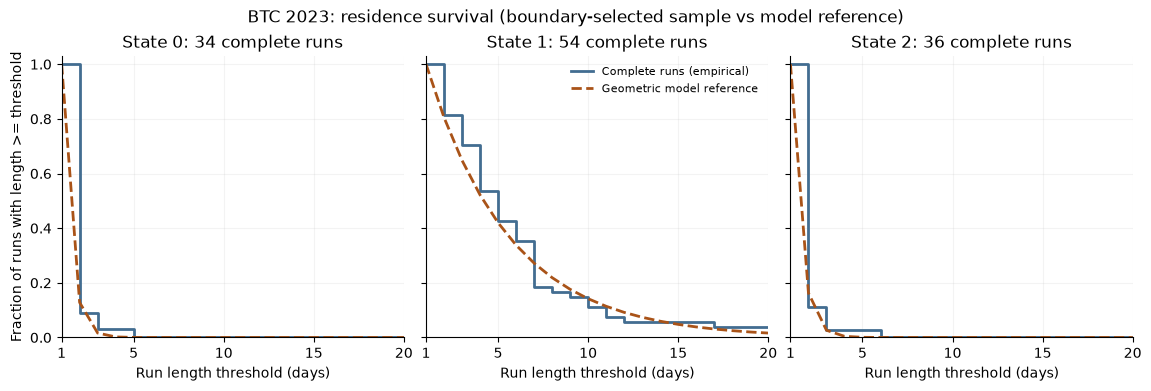

In [47]:
if residence is None:
    print("Residence diagnostic unavailable; no observed curve or simulation plot is shown.")
else:
    with plt.rc_context({"font.family": "DejaVu Sans", "font.size": 10,
                         "axes.spines.top": False, "axes.spines.right": False}):
        fig, axes = plt.subplots(1, 3, figsize=(11.4, 3.8), sharey=True, layout="constrained")
        for i, ax in enumerate(axes):
            x = np.r_[1, residence["durations"]]
            ax.step(x, np.r_[1, residence["empirical_survival"][i]], where="post",
                    color="#426D91", linewidth=2, label="Complete runs (empirical)")
            ax.plot(x, np.r_[1, residence["geometric_survival"][i]], "--",
                    color="#A95318", linewidth=2, label="Geometric model reference")
            ax.set_title(f"State {i}: {residence['run_counts'][i]} complete runs")
            ax.set_xlabel("Run length threshold (days)")
            ax.set_xlim(1, part_b_config["max_duration"])
            ax.set_ylim(0, 1.03)
            ax.set_xticks([1, 5, 10, 15, 20])
            ax.grid(alpha=.15)
        axes[0].set_ylabel("Fraction of runs with length >= threshold")
        axes[1].legend(loc="upper right", frameon=False, fontsize=8)
        fig.suptitle("BTC 2023: residence survival (boundary-selected sample vs model reference)", fontsize=12)
        display(fig)
        plt.close(fig)

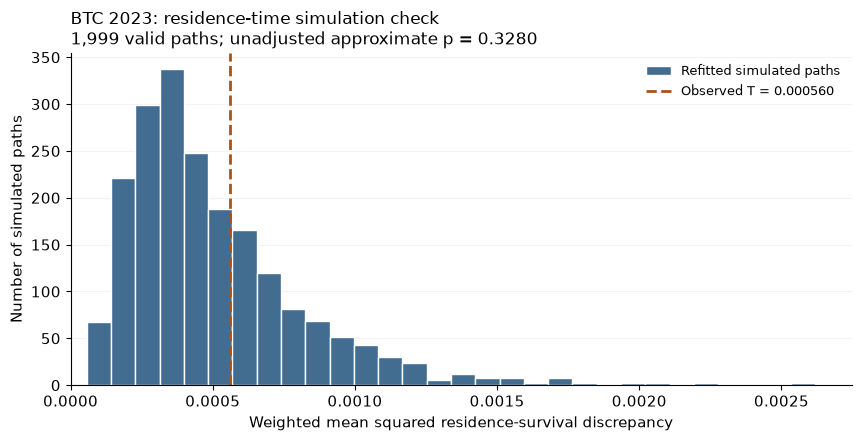

In [48]:
if residence is None:
    print("Residence diagnostic unavailable; no observed curve or simulation plot is shown.")
else:
    with plt.rc_context({"font.family": "DejaVu Sans", "font.size": 11,
                         "axes.spines.top": False, "axes.spines.right": False}):
        fig, ax = plt.subplots(figsize=(8.5, 4.3), layout="constrained")
        valid = residence_result["simulated_statistics"]
        valid = valid[np.isfinite(valid)]
        ax.hist(valid, bins=30, color="#426D91", edgecolor="white", label="Refitted simulated paths")
        ax.axvline(residence["statistic"], color="#A95318", linestyle="--", linewidth=2,
                   label=f"Observed T = {residence['statistic']:.6f}")
        ax.set_xlim(left=0)
        ax.set_xlabel("Weighted mean squared residence-survival discrepancy")
        ax.set_ylabel("Number of simulated paths")
        p_text = f"unadjusted approximate p = {residence_result['p_value']:.4f}" if not residence_result["invalid_simulations"] else "p withheld: invalid simulations"
        ax.set_title(f"BTC 2023: residence-time simulation check\n{len(valid):,} valid paths; {p_text}", loc="left", fontsize=12)
        ax.grid(axis="y", alpha=.15)
        ax.set_axisbelow(True)
        ax.legend(frameon=False, fontsize=9)
        display(fig)
        plt.close(fig)

## 12. Part B: joint conclusions and additional development windows

### 12.1 Holm adjustment for the two primary development diagnostics

Sort the two raw p-values, multiply them by 2 and 1 respectively, take a
cumulative maximum and cap at 1; restore the original test order. Reject a
particular implication only if its adjusted p-value is at most 0.05.
If either p-value is unavailable, withhold the entire family's joint decision.
Holm addresses multiplicity; it does not make approximate bootstrap p-values
exact, and these previously used data are still exploratory research evidence.

In [49]:
def holm_adjust(p_values: pd.Series, alpha: float = 0.05) -> pd.DataFrame:
    """Adjust one prespecified family; never shrink it because a p-value is missing."""
    if not isinstance(p_values, pd.Series) or len(p_values) == 0 or not p_values.index.is_unique:
        raise ValueError("Provide a nonempty Series with unique test names.")
    if isinstance(alpha, (bool, np.bool_)) or not np.isfinite(alpha) or not 0 < alpha < 1:
        raise ValueError("alpha must lie strictly between zero and one.")
    values = p_values.to_numpy(dtype=float, na_value=np.nan)
    if np.isinf(values).any() or ((values < 0) | (values > 1)).any():
        raise ValueError("p-values must be in [0, 1] or missing.")
    available = not np.isnan(values).any()
    adjusted = np.full(len(values), np.nan)
    reject = pd.array([pd.NA] * len(values), dtype="boolean")
    if available:
        order = np.argsort(values, kind="stable")
        sorted_adjusted = np.maximum.accumulate((len(values) - np.arange(len(values))) * values[order])
        adjusted[order] = np.minimum(1.0, sorted_adjusted)
        reject = pd.array(adjusted <= alpha, dtype="boolean")
    return pd.DataFrame({"raw_p": values, "holm_p": adjusted, "reject": reject,
                         "family_available": available}, index=p_values.index)

In [50]:
primary_holm = holm_adjust(pd.Series({
    "CK": ck_result["p_value"], "Residence": residence_result["p_value"],
}), alpha=part_b_config["alpha"])
display(primary_holm)

,raw_p,holm_p,reject,family_available
CK,0.809,0.809,False,True
Residence,0.328,0.656,False,True


### 12.2 Fixed auxiliary windows: 2020, 2021, 2022, and pooled 2020–2023

These four windows were listed before executing their diagnostics. They form
one separate **exploratory family of eight tests**, corrected together with
Holm. They are not independent confirmation or extra chances to select a
favorable window. If any p-value is unavailable, that whole family's joint
decision is withheld rather than reducing its size.

States are computed once from the full development price history before
selecting windows. The first usable state is January 22, 2020, so the first
annual window has 345 days; 2021–2023 each have 365 days. The pooled window
contains 1,440 days and assumes a single matrix across four years. A pooled
rejection may reflect time variation rather than additional memory.
Part A's rolling predictions and single holdout evaluation stay unchanged.

The same diagnostic wrapper validates every fixed window. Expected incomplete or sparse observed paths are retained as unavailable with zero simulations; unexpected errors still stop execution.


In [51]:
part_b_results = {"2023": {"CK": ck_result, "Residence": residence_result}}
for specification in part_b_config["windows"]:
    if specification["family"] == "primary":
        continue
    part_b_results[specification["name"]] = {
        diagnostic: run_development_diagnostic(
            features["state"], specification["start"], specification["end"], diagnostic, part_b_config)
        for diagnostic in ["CK", "Residence"]
    }

rows = []
for specification in part_b_config["windows"]:
    for diagnostic, result in part_b_results[specification["name"]].items():
        rows.append({**specification, "diagnostic": diagnostic,
            "days": len(pd.date_range(specification["start"], specification["end"])),
            "statistic": np.nan if result["observed"] is None else result["observed"]["statistic"],
            "raw_p": result["p_value"], "simulations": result["n_simulations"],
            "invalid_simulations": result["invalid_simulations"], "exceedances": result["exceedances"],
            "unavailable_reason": result.get("unavailable_reason", "")})
part_b_summary = pd.DataFrame(rows)
part_b_summary["holm_p"] = np.nan
part_b_summary["reject"] = pd.array([pd.NA] * len(part_b_summary), dtype="boolean")
part_b_summary["family_available"] = False
for family in ["primary", "exploratory"]:
    mask = part_b_summary["family"].eq(family)
    adjusted = holm_adjust(part_b_summary.loc[mask, "raw_p"], alpha=part_b_config["alpha"])
    part_b_summary.loc[mask, "holm_p"] = adjusted["holm_p"]
    part_b_summary.loc[mask, "reject"] = adjusted["reject"]
    part_b_summary.loc[mask, "family_available"] = adjusted["family_available"]
display(part_b_summary[["name", "family", "diagnostic", "days", "statistic", "raw_p", "holm_p", "reject", "invalid_simulations"]].round(6))

,name,family,diagnostic,days,statistic,raw_p,holm_p,reject,invalid_simulations
0,2023,primary,CK,365,0.000822,0.8090,0.8090,False,0
1,2023,primary,Residence,365,0.000560,0.3280,0.6560,False,0
2,2020,exploratory,CK,345,0.003175,0.2895,1.0000,False,0
3,2020,exploratory,Residence,345,0.000572,0.0925,0.6475,False,0
4,2021,exploratory,CK,365,0.004216,0.1755,1.0000,False,0
5,2021,exploratory,Residence,365,0.000213,0.4030,1.0000,False,0
6,2022,exploratory,CK,365,0.000764,0.8350,1.0000,False,0
7,2022,exploratory,Residence,365,0.000214,0.7730,1.0000,False,0
8,pooled_2020_2023,exploratory,CK,1440,0.000292,0.7280,1.0000,False,0
9,pooled_2020_2023,exploratory,Residence,1440,0.000158,0.0795,0.6360,False,0


### 12.3 Save the complete development record

Save all ten statistics and decisions, every simulated statistic (including
missing values), per-state run counts, the primary run table, and the survival
curves behind the chart. These are reproducible development results, not the
single holdout run. The manifest records source/config/protocol/function hashes.
A timestamp and hash are an audit trail, not proof of independent preregistration.

In [52]:
import ast
import platform
from datetime import datetime, timezone

part_b_output = ROOT / "results/part_b_development"
part_b_output.mkdir(parents=True, exist_ok=True)
part_b_summary.to_csv(part_b_output / "diagnostics.csv", index=False)
residence_runs.to_csv(part_b_output / "residence_runs_2023.csv", index=False)
run_details, simulations = [], []
for name, diagnostics in part_b_results.items():
    for diagnostic, result in diagnostics.items():
        simulations.extend({"window": name, "diagnostic": diagnostic, "simulation": b + 1,
                            "statistic": statistic} for b, statistic in enumerate(result["simulated_statistics"]))
    observed = diagnostics["Residence"]["observed"]
    if observed is not None:
        for i in range(3):
            run_details.append({"window": name, "state": i,
                "complete_runs": int(observed["run_counts"][i]), "run_weight": observed["run_weights"][i],
                "P_ii": observed["P1"][i, i]})
pd.DataFrame(run_details, columns=["window", "state", "complete_runs", "run_weight", "P_ii"]).to_csv(part_b_output / "run_counts.csv", index=False)
pd.DataFrame(simulations, columns=["window", "diagnostic", "simulation", "statistic"]).to_csv(part_b_output / "simulated_statistics.csv", index=False)
survival_rows = [] if residence is None else [{"state": i, "duration": int(ell),
    "empirical_survival": residence["empirical_survival"][i, j],
    "geometric_reference": residence["geometric_survival"][i, j]}
    for i in range(3) for j, ell in enumerate(residence["durations"])]
pd.DataFrame(survival_rows, columns=["state", "duration", "empirical_survival", "geometric_reference"]).to_csv(part_b_output / "survival_2023.csv", index=False)
notebook_on_disk = json.loads((ROOT / "notebooks/01_states_and_first_passage.ipynb").read_text())
research_sources = ["".join(cell["source"]) for cell in notebook_on_disk["cells"]
                    if cell["cell_type"] == "code" and "research-functions" in cell.get("metadata", {}).get("tags", [])]
manifest = {
    "executed_at_utc": datetime.now(timezone.utc).isoformat(), "scope": "BTC development only; 2020-2023",
    "source": str(csv_path.relative_to(ROOT)), "source_sha256": source_sha256,
    "config": part_b_config, "python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
    "protocol_sha256": hashlib.sha256((ROOT / "research/protocol_part_b.md").read_bytes()).hexdigest(),
    "config_sha256": hashlib.sha256((ROOT / "research/part_b_config.json").read_bytes()).hexdigest(),
    "research_function_sources_sha256": hashlib.sha256(json.dumps(research_sources, ensure_ascii=False).encode()).hexdigest(),
    "part_a_frozen_commit": "af49df367c9792054b7a9cd8a90951dd1719d22c",
    "invalid_reasons": {name: diagnostics["Residence"].get("invalid_reason_counts", {}) for name, diagnostics in part_b_results.items()},
    "caveat": "Approximate fitted-null calibration on previously used development data; no proof of Markovity.",
}
manifest["output_sha256"] = {p.name: hashlib.sha256(p.read_bytes()).hexdigest() for p in sorted(part_b_output.glob("*.csv"))}
(part_b_output / "manifest.json").write_text(json.dumps(manifest, indent=2) + "\n")
assert len(part_b_summary) == 10
assert part_b_summary.groupby("family").size().to_dict() == {"exploratory": 8, "primary": 2}
if residence is not None:
    assert np.allclose(residence["P1"], P)
assert hashlib.sha256(csv_path.read_bytes()).hexdigest() == source_sha256
print("Saved development-only Part B results to", part_b_output.relative_to(ROOT))

Saved development-only Part B results to results/part_b_development


### Reading the results

| 2023 diagnostic | Discrepancy | Raw approximate p | Holm-adjusted p |
|---|---:|---:|---:|
| CK | 0.00082223 | 0.8090 | 0.8090 |
| Residence | 0.00056047 | 0.3280 | 0.6560 |

Neither primary implication is rejected at the declared 0.05 level. This is non-rejection, not evidence that the process is proven Markov.

None of the eight auxiliary diagnostics rejects after their separate Holm adjustment. Every window used 1,999 simulations per available diagnostic; consult the
full table for invalid counts and availability. The pooled window assumes one
matrix across four years, and is not independent confirmation of the annual
results. Non-rejection cannot rule out other forms of memory or time variation;
rejection would not by itself determine predictive performance. Neither family
can change frozen Part A.

**Next learning step:** section 11.1, identifying complete and boundary-truncated
runs, followed by the scalar statistic, its simulated reference distribution,
and the Holm correction.


Execution and presentation: all notebook calculations use development data only. Saved numerical tables and embedded figures are checked after execution. Full HTML browser layout has not been visually inspected. Gate dry-check and synthetic gate tests do not decode real holdout prices.
